In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.feature_extraction import DictVectorizer
#Metricas
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

# Exploratory Data Analysis (EDA)

In [2]:
#Load dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
#Missing values
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [5]:
df.shape

(100000, 9)

In [6]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [7]:
df.describe().round(3)

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000
mean,41.886,0.075,0.039,27.321,5.528,138.058,0.085
std,22.517,0.263,0.195,6.637,1.071,40.708,0.279
min,0.080,0.000,0.000,10.010,3.500,80.000,0.000
25%,24.000,0.000,0.000,23.630,4.800,100.000,0.000
50%,43.000,0.000,0.000,27.320,5.800,140.000,0.000
75%,60.000,0.000,0.000,29.580,6.200,159.000,0.000
max,80.000,1.000,1.000,95.690,9.000,300.000,1.000


In [8]:
#Split the dataset's columns in numerical and categorical columns
numerical = ['bmi', 'age', 'blood_glucose_level','HbA1c_level']
categorical = ['gender', 'hypertension', 'heart_disease', 'smoking_history']

In [9]:
df[categorical].nunique()

gender             3
hypertension       2
heart_disease      2
smoking_history    6
dtype: int64

# Distribucion de las variables

In [10]:
#Variable objetivo
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [11]:
#Varibles categoricas
df['hypertension'].value_counts()

hypertension
0    92515
1     7485
Name: count, dtype: int64

In [12]:
df['heart_disease'].value_counts()

heart_disease
0    96058
1     3942
Name: count, dtype: int64

In [13]:
df['smoking_history'].value_counts()

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

In [14]:
#Distribucion de variables numericas
def rango(df):
    return max(df) - min(df)
df[numerical].agg(['max','min',rango,'mean','median','std'])

,bmi,age,blood_glucose_level,HbA1c_level
max,95.690000,80.000000,300.000000,9.000000
min,10.010000,0.080000,80.000000,3.500000
rango,85.680000,79.920000,220.000000,5.500000
mean,27.320767,41.885856,138.058060,5.527507
median,27.320000,43.000000,140.000000,5.800000
std,6.636783,22.516840,40.708136,1.070672


# Revision variables numericas

In [15]:
df[numerical].mode()

,bmi,age,blood_glucose_level,HbA1c_level
0,27.32,80.0,130,6.6


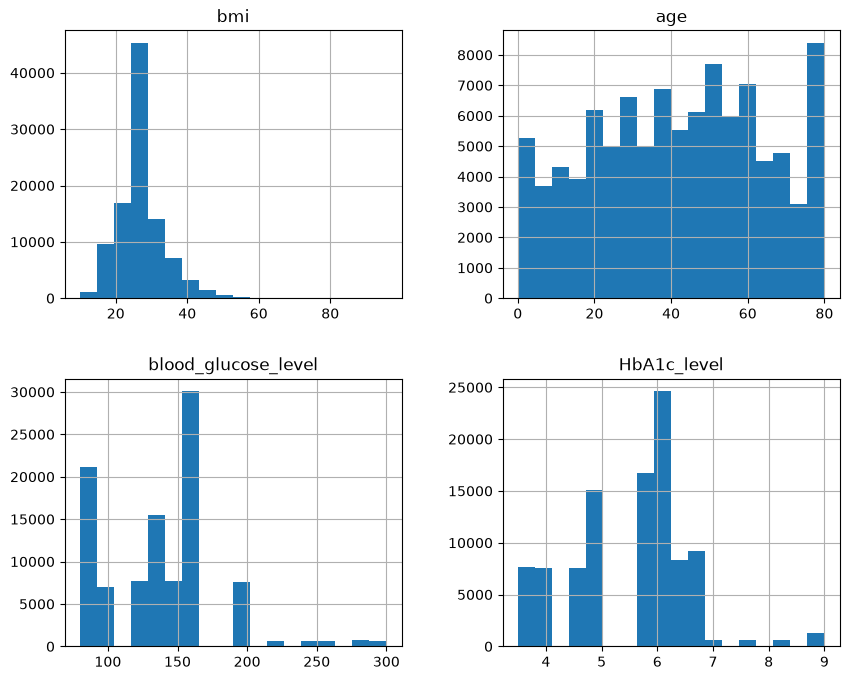

In [16]:
df[numerical].hist(figsize=(10, 8), bins=18)
plt.show()

In [17]:
#Duplicated data
df.duplicated().sum()

np.int64(3854)

In [18]:
df_duplicados = df[df.duplicated(keep=False)]
df_duplicados.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
10,Female,53.0,0,0,never,27.32,6.1,85,0
14,Female,76.0,0,0,No Info,27.32,5.0,160,0
18,Female,42.0,0,0,No Info,27.32,5.7,80,0
41,Male,5.0,0,0,No Info,27.32,6.6,130,0


In [19]:
#Eliminando duplicados
df.drop_duplicates(inplace=True)

In [20]:
df[numerical].agg(['max','min',rango,'mean','median','std'])

,bmi,age,blood_glucose_level,HbA1c_level
max,95.690000,80.000000,300.000000,9.000000
min,10.010000,0.080000,80.000000,3.500000
rango,85.680000,79.920000,220.000000,5.500000
mean,27.321461,41.794326,138.218231,5.532609
median,27.320000,43.000000,140.000000,5.800000
std,6.767716,22.462948,40.909771,1.073232


In [21]:
df[numerical].mode()

,bmi,age,blood_glucose_level,HbA1c_level
0,27.32,80.0,159,6.6


In [22]:
#Distribucion de variable objetivo despues de eliminar duplicados
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.91178
1    0.08822
Name: proportion, dtype: float64

In [23]:
df['gender'].value_counts()

gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

In [24]:
df[df['gender']=='Other']

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
12669,Other,10.0,0,0,not current,14.09,5.0,140,0
14838,Other,19.0,0,0,No Info,27.32,5.7,158,0
16702,Other,39.0,0,0,not current,31.24,6.2,85,0
18691,Other,10.0,0,0,not current,16.59,6.1,160,0
23266,Other,23.0,0,0,No Info,24.23,6.1,140,0
31985,Other,53.0,0,0,No Info,27.32,6.6,160,0
33805,Other,45.0,0,0,never,27.32,4.0,159,0
34929,Other,47.0,0,0,never,36.76,6.6,90,0
35006,Other,47.0,0,0,never,36.76,3.5,200,0
40337,Other,18.0,0,0,not current,30.19,6.1,90,0


Se observa que el genero- other no tienen diabetes (0) quiere decir que el modelo aprenderá que cada persona con el genero other nunca tendrá diabetes por lo que es mejor eliminar la categoria.

In [25]:
df = df[df['gender']!='Other']

In [26]:
df.to_csv('diabetes_prediction_dataset_cleaned.csv', index=False)

# Feature importance

In [27]:
df.shape

(96128, 9)

In [28]:
from sklearn.model_selection import train_test_split

df_full_train , df_test = train_test_split(df, test_size=0.20, random_state=1)
df_train , df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [29]:
len(df_train), len(df_val), len(df_test)

(57676, 19226, 19226)

In [30]:
#Global rate risk of diabetes
global_diabetes = df_full_train['diabetes'].mean()
print(global_diabetes)

0.08724090400769811


In [31]:
from IPython.display import display

In [32]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).diabetes.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_diabetes
    df_group['risk'] = df_group['mean'] / global_diabetes
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
Female,0.078262,44926,-0.008979,0.897080
Male,0.099856,31976,0.012615,1.144602




hypertension


,mean,count,diff,risk
hypertension,,,,
0,0.071125,70946,-0.016116,0.815266
1,0.279214,5956,0.191973,3.200497




heart_disease


,mean,count,diff,risk
heart_disease,,,,
0,0.077290,73774,-0.009951,0.885939
1,0.321931,3128,0.234690,3.690138




smoking_history


,mean,count,diff,risk
smoking_history,,,,
No Info,0.043663,26361,-0.043578,0.500488
current,0.100312,7367,0.013071,1.149830
ever,0.115360,3164,0.028119,1.322319
former,0.170241,7460,0.083000,1.951393
never,0.096162,27516,0.008921,1.102261
not current,0.106873,5034,0.019632,1.225036


# Mutual information

In [33]:
from sklearn.metrics import mutual_info_score

In [34]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df_full_train.diabetes)

In [35]:
mi = df_full_train[categorical].apply(mutual_info_diabetes_score)
mi.sort_values(ascending=False)

hypertension       0.013572
heart_disease      0.009518
smoking_history    0.008904
gender             0.000704
dtype: float64

# Variables numericas 

In [36]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(df_full_train[numerical], df_full_train.diabetes, discrete_features=False,random_state=1)
mi_result = pd.Series(mi_scores, index=df_full_train[numerical].columns).sort_values(ascending=False)
print("Importancia por Información Mutua:")
print(mi_result)

Importancia por Información Mutua:
HbA1c_level            0.132855
blood_glucose_level    0.116561
age                    0.041849
bmi                    0.023325
dtype: float64


# one hot enconding

In [38]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.diabetes.values
y_val = df_val.diabetes.values
y_test = df_test.diabetes.values

del df_train['diabetes']
del df_val['diabetes']
del df_test['diabetes']

In [39]:
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Model selection

In [41]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [42]:
y_pred = model.predict_proba(X_val)[:, 1]
diabetes_decision = (y_pred >= 0.5)
(y_val == diabetes_decision).mean()

np.float64(0.8884843441173411)

In [43]:
y_pred_values = np.where(y_pred >= 0.5, 1, 0)
y_pred_values



array([0, 1, 1, ..., 1, 0, 0], shape=(19226,))

In [44]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_val, y_pred_values)

array([[15717,  1937],
       [  207,  1365]])

In [45]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val, y_pred)

0.958063011330895

In [46]:
from sklearn.model_selection import cross_validate
cv_scores = cross_validate(model, X_train, y_train, cv=5, scoring=['accuracy', 'precision', 'recall', 'f1'])

accuracy = cv_scores['test_accuracy'].mean()
precision = cv_scores['test_precision'].mean()
recall = cv_scores['test_recall'].mean()
f1 = cv_scores['test_f1'].mean()

accuracy, precision, recall, f1

(np.float64(0.8875615505964781),
 np.float64(0.4349738407247763),
 np.float64(0.8750222589310409),
 np.float64(0.5810335201361684))